# Correction pour rendu 3 - années 2020 - 2021

- prener cecu pour la merge si on decide de le refaire: effectif_metropole_2020_2024_tsage_toussexe_respiratoire

In [1]:
#import des librairies
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns

In [2]:
df_effectifs = pd.read_csv(
    "../data/raw/Sante/effectifs.csv", sep=';', 
)
df_effectifs.head()

,annee,patho_niv1,patho_niv2,patho_niv3,top,cla_age_5,sexe,region,dept,Ntop,Npop,prev,Niveau prioritaire,libelle_classe_age,libelle_sexe,tri
0,2020,Maladies psychiatriques,Troubles psychotiques,Troubles psychotiques,PSY_PSC_IND,50-54,2,1,971,280.0,17040,1.643,"2,3",de 50 à 54 ans,femmes,48.0
1,2020,Maladies psychiatriques,Troubles psychotiques,Troubles psychotiques,PSY_PSC_IND,50-54,2,3,999,50.0,6090,0.771,"2,3",de 50 à 54 ans,femmes,48.0
2,2020,Maladies psychiatriques,Troubles psychotiques,Troubles psychotiques,PSY_PSC_IND,50-54,2,4,974,390.0,32630,1.205,"2,3",de 50 à 54 ans,femmes,48.0
3,2020,Maladies psychiatriques,Troubles psychotiques,Troubles psychotiques,PSY_PSC_IND,50-54,2,11,77,350.0,48230,0.732,"2,3",de 50 à 54 ans,femmes,48.0
4,2020,Maladies psychiatriques,Troubles psychotiques,Troubles psychotiques,PSY_PSC_IND,50-54,2,11,91,400.0,43370,0.927,"2,3",de 50 à 54 ans,femmes,48.0


In [3]:
df_effectifs.info()

<class 'pandas.DataFrame'>
RangeIndex: 5796000 entries, 0 to 5795999
Data columns (total 16 columns):
 #   Column              Dtype  
---  ------              -----  
 0   annee               int64  
 1   patho_niv1          str    
 2   patho_niv2          str    
 3   patho_niv3          str    
 4   top                 str    
 5   cla_age_5           str    
 6   sexe                int64  
 7   region              int64  
 8   dept                str    
 9   Ntop                float64
 10  Npop                int64  
 11  prev                float64
 12  Niveau prioritaire  str    
 13  libelle_classe_age  str    
 14  libelle_sexe        str    
 15  tri                 float64
dtypes: float64(3), int64(4), str(9)
memory usage: 1.4 GB


In [4]:
#Quelles sont les valeurs uniques pour les pathologies de niveau 1
print(df_effectifs["patho_niv1"].unique())

<ArrowStringArray>
[                                                                                         'Maladies psychiatriques',
                                                           'Maladies respiratoires chroniques (hors mucoviscidose)',
                                                                'Maladies inflammatoires ou rares ou infection VIH',
                                                                                           'Maladies neurologiques',
 'Pas de pathologie repérée, traitement, maternité, hospitalisation ou traitement antalgique ou anti-inflammatoire',
                                                                                   'Total consommants tous régimes',
                                                                                                          'Cancers',
                                                                                                          'Diabète',
                                             

1. Filtrage sur patho_niv1
Le fichier est assez lourd, pour ne pas avoir à manipuler tout les données qui ne seront pas utiles pour notre projet, je commence par faire 2 df differentes:
 un avec uniquement les maladies respiratoires chroniques (b), et l'autre qui contient les hospitalisations pour Covid-19, Traitement antalgique ou anti-inflammatoire et Cancers (a)

In [5]:
# 1. Définir les catégories à explorer
pathologies = [
    "Maladies respiratoires chroniques (hors mucoviscidose)",
    "Hospitalisation pour Covid-19",
    "Traitements antalgiques ou anti-inflammatoires (hors pathologies, traitements, maternité ou hospitalisations)",
    "Cancers"
]
pathologie_respi = [
    "Maladies respiratoires chroniques (hors mucoviscidose)"
]

# 1. a) creation nouvelle df filtré pour 4 categories selectionnées
df_effectifs_filtre_patho = df_effectifs[
    df_effectifs["patho_niv1"].isin(pathologies)
].copy()



# 1.b) creation nouvelle df filtré pour les maladies respiratoires uniquement

df_respi = df_effectifs[
    df_effectifs["patho_niv1"].isin(pathologie_respi)
]


In [ ]:
#Exportation des 2 fichiers
df_effectifs_filtre_patho.to_csv("../data/sauvegardes_processing/df_effectifs_filtre_patho.csv", sep=",", index=False)

df_respi.to_csv("df_respi", sep=",", index=False)

2. Nettoyage des colonnes redondantes
Je continue le preprocessing avec df_respi.

a) Niveau pathologie et categorie top: la catégorie "Maladie respiratoires chroniques" regroupe plusieurs maladies respiratoires chroniques : elle ne permet pas d’isoler précisément l’asthme, l’allergie ou la bronchiolite.

In [7]:
print("Original :", df_effectifs.shape)

print("Respi:", df_respi.shape)

df_respi.head(5)

Original : (5796000, 16)
Respi: (75600, 16)


,annee,patho_niv1,patho_niv2,patho_niv3,top,cla_age_5,sexe,region,dept,Ntop,Npop,prev,Niveau prioritaire,libelle_classe_age,libelle_sexe,tri
1259,2020,Maladies respiratoires chroniques (hors mucovi...,Maladies respiratoires chroniques (hors mucovi...,Maladies respiratoires chroniques (hors mucovi...,RES_CAT_EXC,00-04,1,2,972,470.0,8310,5.679,"1,2,3",de 0 à 4 ans,hommes,10.0
1260,2020,Maladies respiratoires chroniques (hors mucovi...,Maladies respiratoires chroniques (hors mucovi...,Maladies respiratoires chroniques (hors mucovi...,RES_CAT_EXC,00-04,1,6,999,90.0,8130,1.046,"1,2,3",de 0 à 4 ans,hommes,10.0
1261,2020,Maladies respiratoires chroniques (hors mucovi...,Maladies respiratoires chroniques (hors mucovi...,Maladies respiratoires chroniques (hors mucovi...,RES_CAT_EXC,00-04,1,11,92,3080.0,52210,5.899,"1,2,3",de 0 à 4 ans,hommes,10.0
1262,2020,Maladies respiratoires chroniques (hors mucovi...,Maladies respiratoires chroniques (hors mucovi...,Maladies respiratoires chroniques (hors mucovi...,RES_CAT_EXC,00-04,1,11,95,2370.0,45900,5.168,"1,2,3",de 0 à 4 ans,hommes,10.0
1263,2020,Maladies respiratoires chroniques (hors mucovi...,Maladies respiratoires chroniques (hors mucovi...,Maladies respiratoires chroniques (hors mucovi...,RES_CAT_EXC,00-04,1,11,999,21150.0,393510,5.373,"1,2,3",de 0 à 4 ans,hommes,10.0


In [8]:
# Verification des souscategories des pathologies

colonnes = ["patho_niv1", "patho_niv2", "patho_niv3", "top"]

for col in colonnes:
    print(f"\n--- {col} ---")
    print(df_respi[col].value_counts(dropna=False))


--- patho_niv1 ---
patho_niv1
Maladies respiratoires chroniques (hors mucoviscidose)    75600
Name: count, dtype: int64

--- patho_niv2 ---
patho_niv2
Maladies respiratoires chroniques (hors mucoviscidose)    75600
Name: count, dtype: int64

--- patho_niv3 ---
patho_niv3
Maladies respiratoires chroniques (hors mucoviscidose)    75600
Name: count, dtype: int64

--- top ---
top
RES_CAT_EXC    75600
Name: count, dtype: int64


In [9]:
# Verification si il y a plusieurs sous-categories lié au patho_niv1
df_respi[colonnes].drop_duplicates()

,patho_niv1,patho_niv2,patho_niv3,top
1259,Maladies respiratoires chroniques (hors mucovi...,Maladies respiratoires chroniques (hors mucovi...,Maladies respiratoires chroniques (hors mucovi...,RES_CAT_EXC


--> Entre les 4 colonnes patho_niv1, patho_niv2, patho_niv3 et top les informations sont redontandtes, je vais garder la categorie "top" qui contient le code et creer un colonne "pathologie" avec un nom plus court pour la pathologie  et supprimer le reste (patho_niv1, patho_niv2, patho_niv3)



1. Nettoyage
a) Supression colonnes patho_niv1, patho_niv2, patho_niv3, creation colonne pathologie
b) --> libellées classe d_age et libelle_sexe car ils sont redondant et reconstituables.

Je garde la colonne "region" à cet etape pour pas perdre l'info des aggregations territoriaux

In [10]:
#creation d'un copy de travail
df_respi_travail = df_respi.copy()

#creation d'une colonnne "pathologie"
df_respi_travail["pathologie"] = "Maladie_Respi_Chronique"

#Supresson des colonnes: "libelle_classe_age","libelle_sexe","patho_niv1","patho_niv2", "patho_niv3", "Niveau prioritaire", "tri"
df_respi_travail = df_respi_travail.drop(columns=["libelle_classe_age", "libelle_sexe", "patho_niv1", "patho_niv2", "patho_niv3","Niveau prioritaire", "tri" ])

display(df_respi_travail.info())
display(df_respi_travail.head(5))


<class 'pandas.DataFrame'>
Index: 75600 entries, 1259 to 5759926
Data columns (total 10 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   annee       75600 non-null  int64  
 1   top         75600 non-null  str    
 2   cla_age_5   75600 non-null  str    
 3   sexe        75600 non-null  int64  
 4   region      75600 non-null  int64  
 5   dept        75600 non-null  str    
 6   Ntop        75421 non-null  float64
 7   Npop        75600 non-null  int64  
 8   prev        75421 non-null  float64
 9   pathologie  75600 non-null  str    
dtypes: float64(2), int64(4), str(4)
memory usage: 9.4 MB


None

,annee,top,cla_age_5,sexe,region,dept,Ntop,Npop,prev,pathologie
1259,2020,RES_CAT_EXC,00-04,1,2,972,470.0,8310,5.679,Maladie_Respi_Chronique
1260,2020,RES_CAT_EXC,00-04,1,6,999,90.0,8130,1.046,Maladie_Respi_Chronique
1261,2020,RES_CAT_EXC,00-04,1,11,92,3080.0,52210,5.899,Maladie_Respi_Chronique
1262,2020,RES_CAT_EXC,00-04,1,11,95,2370.0,45900,5.168,Maladie_Respi_Chronique
1263,2020,RES_CAT_EXC,00-04,1,11,999,21150.0,393510,5.373,Maladie_Respi_Chronique


1. Nettoyage
c) Supprimer les annees pas retenus par l'equipe, garder la periode 2020 -2024


In [11]:
# Garder uniquement les années choisies
df_annees = df_respi_travail["annee"].isin([2020, 2021, 2022, 2023, 2024])

df_respi_travail = df_respi_travail.loc[df_annees].copy()

# Vérifier les années restantes
print(sorted(df_respi_travail["annee"].unique()))

[np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024)]


2. Aggregats territoriaux
a) Verifications

Comme le jeu de données contient trois niveaux d’agrégation territoriale : départemental, régional et national. Les codes dept = 999 et region ≠ 99 semblent correspondre aux totaux régionaux, tandis que dept = 999 et region = 99 représenteraient le total national. Il faut distinguer ces niveaux lors des analyses pour éviter les doubles comptages.

In [12]:
#1. Controler 
# Examiner les couples département–région: afficher chaque association departement-region avec le nombre de ligne correspondant

# Copie pour les contrôles ; codes conservés comme chaînes
df_controle = df_respi_travail.copy()

for col in ["dept", "region"]:
    df_controle[col] = df_controle[col].astype("string").str.strip()  #transformer en texte et retierer les espaces eventuelles

couples = (
    df_controle.groupby(["dept", "region"], dropna=False)       #rassemble les lignes ayant le même couple département–région, on garde les lignes avec les NA
    .size()                                                     #compte les lignes de chaque groupes
    .reset_index(name="nombre_lignes")                          #resultats en DF avec 3 colonnes dept, region et nombre_lignes
)

display(couples.sort_values(["region", "dept"]))

# Examiner séparément les lignes supposées régionales et nationales
display(couples.loc[couples["dept"]=="999"])

,dept,region,nombre_lignes
96,971,1,315
101,999,1,315
75,75,11,315
77,77,11,315
78,78,11,315
...,...,...,...
117,999,93,315
28,2A,94,315
29,2B,94,315
118,999,94,315


,dept,region,nombre_lignes
101,999,1,315
102,999,11,315
103,999,2,315
104,999,24,315
105,999,27,315
106,999,28,315
107,999,3,315
108,999,32,315
109,999,4,315
110,999,44,315


La conclusion : les lignes dept = 999 doivent être mises à part pour une analyse départementale.

Verifications:
- chaque département est-il toujours associé à une seule région ?

In [13]:
#  chaque département est-il toujours associé à une seule région ?


departements = df_controle.loc[
    df_controle["dept"].notna()         #code de departement est renseigné et
    & (df_controle["dept"] != "999")     #le code département est différent de "999"
].copy()

regions_par_departement = (
    departements.groupby("dept")
    .agg(
        nombre_regions=("region", lambda s: s.nunique(dropna=False)),           #combien de valeurs différentes apparaissent dans region
        codes_region=("region", lambda s: s.drop_duplicates().tolist())         #la liste de ces valeurs, sans répétition
    )
)

# Une table vide signifie qu'aucun département n'a plusieurs régions
display(
    regions_par_departement.loc[
        regions_par_departement["nombre_regions"] != 1
    ]
)

# Repérer aussi les départements sans région ou associés à "99"
display(
    departements.loc[
        departements["region"].isna()
        | (departements["region"] == "99"),     #departements avec un region manquant ou egale à 99
        ["dept", "region"]
    ].drop_duplicates()
)

,nombre_regions,codes_region
dept,,


,dept,region


chaque departement est associé à une seule region, et il n'y a pas de departement non renseigné avec le code 99

--> comparer les totaux publiés aux sommes des départements, séparément pour chaque année 

In [14]:
# Selectionner tous age et tous sexe
base = df_controle.loc[
    (df_controle["cla_age_5"].astype("string") == "tsage")       #selectionner tous age et
    & (df_controle["sexe"].astype("string") == "9")              #tout sexe
].copy()


#Vérifier qu’une même observation n’apparaît pas plusieurs fois
cles = ["annee", "region" , "dept"]


doublons = base.duplicated(cles, keep=False)
display(base.loc[doublons])

if doublons.any():
    raise ValueError("Des doublons doivent être examinés avant de calculer les sommes.")


,annee,top,cla_age_5,sexe,region,dept,Ntop,Npop,prev,pathologie


Resultat: La combinaison année + région + département est unique. Le tableu vide signifie que aucun doublon n'a ete trouvé

2. Aggregats territoriaux
b) Separation les 3 niveaux territoriaux

In [15]:
#Separer les 3 niveux territorieaux: les trois tables sont séparées pour que les totaux publiés ne soient jamais inclus dans la somme des départements.

# Lignes départementales
details = base.loc[
    base["dept"].notna()
    & (base["dept"] != "999")
    & base["region"].notna()
    & (base["region"] != "99")
].copy()

# Totaux régionaux supposés
totaux_regionaux = base.loc[
    (base["dept"] == "999")
    & base["region"].notna()
    & (base["region"] != "99")
].copy()

# Total national supposé
total_national = base.loc[
    (base["dept"] == "999")
    & (base["region"] == "99")
].copy()

In [16]:
#  Additionner les départements pour chaque année et région
sommes_regions = (
    details.groupby(["annee", "region"])[["Ntop", "Npop"]]
    .agg(lambda colonne: colonne.sum(skipna=False))
    .reset_index()
)

display(sommes_regions)

,annee,region,Ntop,Npop
0,2020,1,18580.0,377810
1,2020,11,568350.0,12038820
2,2020,2,14520.0,354950
3,2020,24,134930.0,2497000
4,2020,27,148420.0,2706220
...,...,...,...,...
85,2024,75,431870.0,6134910
86,2024,76,406520.0,6131500
87,2024,84,448260.0,8094330
88,2024,93,342540.0,5401550


In [17]:
#  Mettre les sommes et les totaux publiés côte à côte
controle_regions = sommes_regions.merge(
    totaux_regionaux[["annee", "region", "Ntop", "Npop"]],
    on=["annee", "region"],
    how="outer",
    suffixes=("_somme_departements", "_publie"),    #distingues les sommes calculés des valeurs publiés
    validate="one_to_one"                           #vérifie qu’il existe au maximum une ligne de chaque côté pour chaque année–région
)

# Calculer les differences

controle_regions["ecart_Ntop"] = (
    controle_regions["Ntop_somme_departements"]
    - controle_regions["Ntop_publie"]
)

controle_regions["ecart_Npop"] = (
    controle_regions["Npop_somme_departements"]
    - controle_regions["Npop_publie"]
)

display(controle_regions)
controle_regions.info()


,annee,region,Ntop_somme_departements,Npop_somme_departements,Ntop_publie,Npop_publie,ecart_Ntop,ecart_Npop
0,2020,1,18580.0,377810,18580.0,377810,0.0,0
1,2020,11,568350.0,12038820,568340.0,12038820,10.0,0
2,2020,2,14520.0,354950,14520.0,354950,0.0,0
3,2020,24,134930.0,2497000,134930.0,2497000,0.0,0
4,2020,27,148420.0,2706220,148410.0,2706210,10.0,10
...,...,...,...,...,...,...,...,...
85,2024,75,431870.0,6134910,431870.0,6134900,0.0,10
86,2024,76,406520.0,6131500,406500.0,6131500,20.0,0
87,2024,84,448260.0,8094330,448260.0,8094340,0.0,-10
88,2024,93,342540.0,5401550,342540.0,5401550,0.0,0


<class 'pandas.DataFrame'>
RangeIndex: 90 entries, 0 to 89
Data columns (total 8 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   annee                    90 non-null     int64  
 1   region                   90 non-null     string 
 2   Ntop_somme_departements  90 non-null     float64
 3   Npop_somme_departements  90 non-null     int64  
 4   Ntop_publie              90 non-null     float64
 5   Npop_publie              90 non-null     int64  
 6   ecart_Ntop               90 non-null     float64
 7   ecart_Npop               90 non-null     int64  
dtypes: float64(3), int64(4), string(1)
memory usage: 5.9 KB


In [18]:
#verification si il y a des lignes non calculables

colonnes_valeurs = [
    "Ntop_somme_departements", "Ntop_publie",
    "Npop_somme_departements", "Npop_publie"
]

lignes_na = controle_regions.loc[
    controle_regions[colonnes_valeurs].isna().any(axis=1)
]

display(lignes_na)

,annee,region,Ntop_somme_departements,Npop_somme_departements,Ntop_publie,Npop_publie,ecart_Ntop,ecart_Npop


pas de lignes avec des NA, tout est calculable

In [19]:
#afficher les valeurs non nulles 

lignes_ecarts = controle_regions.loc[
    (controle_regions["ecart_Ntop"].notna()
        & (controle_regions["ecart_Ntop"] != 0))
    |(controle_regions["ecart_Npop"].notna()
        & (controle_regions["ecart_Npop"] != 0)
    )
]

display(lignes_ecarts.sort_values(["annee", "region"])) 



lignes_ecarts.info()

,annee,region,Ntop_somme_departements,Npop_somme_departements,Ntop_publie,Npop_publie,ecart_Ntop,ecart_Npop
1,2020,11,568350.0,12038820,568340.0,12038820,10.0,0
4,2020,27,148420.0,2706220,148410.0,2706210,10.0,10
5,2020,28,204730.0,3228840,204730.0,3228830,0.0,10
7,2020,32,363660.0,5816340,363650.0,5816340,10.0,0
9,2020,44,296220.0,5192550,296220.0,5192560,0.0,-10
10,2020,52,189820.0,3769210,189810.0,3769210,10.0,0
11,2020,53,188490.0,3309050,188480.0,3309040,10.0,10
13,2020,75,359420.0,5926220,359410.0,5926210,10.0,10
14,2020,76,331210.0,5885320,331230.0,5885300,-20.0,20
15,2020,84,375410.0,7899100,375400.0,7899080,10.0,20


<class 'pandas.DataFrame'>
Index: 56 entries, 1 to 89
Data columns (total 8 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   annee                    56 non-null     int64  
 1   region                   56 non-null     string 
 2   Ntop_somme_departements  56 non-null     float64
 3   Npop_somme_departements  56 non-null     int64  
 4   Ntop_publie              56 non-null     float64
 5   Npop_publie              56 non-null     int64  
 6   ecart_Ntop               56 non-null     float64
 7   ecart_Npop               56 non-null     int64  
dtypes: float64(3), int64(4), string(1)
memory usage: 4.1 KB


Resultat de verification de calcul: Sur 72 comparaisons région–année, 44 présentent un écart sur Ntop et/ou Npop entre la somme départementale et le total régional publié. L’origine de ces écarts n’a pas été déterminée. La suite de l’analyse utilise uniquement les observations départementales.

3. Pour la suite - creation de df_respi_departementale en gardeant la ##colonne region pour les regroupements eventuelles

In [20]:
df = df_respi_travail.copy()

# Harmoniser les codes territoriaux sans remplacer les NA
for col in ["dept", "region"]:
    df[col] = df[col].astype("string").str.strip()


# Attribuer un niveau territorial à chaque ligne
df["niveau"] = "a_verifier"

region_connue = df["region"].notna() & (df["region"] != "99")

#on donne la valeur "departement" aux lignes ou le departement est connu, pas egale à 999 et region est connu
df.loc[
    df["dept"].notna() & (df["dept"] !="999") & region_connue,
    "niveau"
] = "departements"

#on donne la valeur "regions" aux lignes ou le departement est  à 999 et region est connu
df.loc[
    df["dept"].eq("999") & region_connue,
    "niveau"
] = "regions"

#etiquette national
df.loc[
    (df["dept"] == "999") & (df["region"] == "99"),
    "niveau"
] = "national"



In [ ]:
# Séparer les niveaux et exporter les CSV

# Séparer les niveaux et exporter les CSV dans un dossier
from pathlib import Path
dossier = Path("exports_effectifs")
dossier.mkdir(exist_ok=True)

# Séparer les données en 4 DataFrames
df_respi_dept = df[df["niveau"] == "departements"].copy()
df_respi_region = df[df["niveau"] == "regions"].copy()
df_respi_national = df[df["niveau"] == "national"].copy()
df_respi_a_verifier = df[df["niveau"] == "a_verifier"].copy()

display(df_respi_dept.head(5))
display(df_respi_region.head(5))
display(df_respi_national.head(5))
display(df_respi_a_verifier.head(5))


#exporter les csv

df_respi_dept.to_csv(../data/sauvegardes_processing/respi_dept.csv", index=False, sep=",")
df_respi_region.to_csv("../data/sauvegardes_processing/respi_region.csv", index=False, sep=",")
df_respi_national.to_csv("../data/sauvegardes_processing/respi_national.csv", index=False, sep=",")
df_respi_a_verifier.to_csv("../data/sauvegardes_processing/respi_a_verifier.csv", index=False, sep=",")



,annee,top,cla_age_5,sexe,region,dept,Ntop,Npop,prev,pathologie,niveau
1259,2020,RES_CAT_EXC,00-04,1,2,972,470.0,8310,5.679,Maladie_Respi_Chronique,departements
1261,2020,RES_CAT_EXC,00-04,1,11,92,3080.0,52210,5.899,Maladie_Respi_Chronique,departements
1262,2020,RES_CAT_EXC,00-04,1,11,95,2370.0,45900,5.168,Maladie_Respi_Chronique,departements
1264,2020,RES_CAT_EXC,00-04,1,24,28,660.0,11640,5.678,Maladie_Respi_Chronique,departements
1265,2020,RES_CAT_EXC,00-04,1,24,36,210.0,4300,4.908,Maladie_Respi_Chronique,departements


,annee,top,cla_age_5,sexe,region,dept,Ntop,Npop,prev,pathologie,niveau
1260,2020,RES_CAT_EXC,00-04,1,6,999,90.0,8130,1.046,Maladie_Respi_Chronique,regions
1263,2020,RES_CAT_EXC,00-04,1,11,999,21150.0,393510,5.373,Maladie_Respi_Chronique,regions
1268,2020,RES_CAT_EXC,00-04,1,27,999,2670.0,65780,4.056,Maladie_Respi_Chronique,regions
1277,2020,RES_CAT_EXC,00-04,1,44,999,5800.0,133300,4.354,Maladie_Respi_Chronique,regions
1299,2020,RES_CAT_EXC,00-04,1,93,999,7380.0,137070,5.385,Maladie_Respi_Chronique,regions


,annee,top,cla_age_5,sexe,region,dept,Ntop,Npop,prev,pathologie,niveau
1561,2020,RES_CAT_EXC,10-14,1,99,999,78850.0,2018970,3.905,Maladie_Respi_Chronique,national
1604,2020,RES_CAT_EXC,10-14,2,99,999,46930.0,1935520,2.425,Maladie_Respi_Chronique,national
1638,2020,RES_CAT_EXC,10-14,9,99,999,125780.0,3954500,3.181,Maladie_Respi_Chronique,national
1788,2020,RES_CAT_EXC,20-24,1,99,999,36770.0,1821560,2.019,Maladie_Respi_Chronique,national
1870,2020,RES_CAT_EXC,20-24,9,99,999,82870.0,3773060,2.196,Maladie_Respi_Chronique,national


,annee,top,cla_age_5,sexe,region,dept,Ntop,Npop,prev,pathologie,niveau


Verification le df_respi_dept

In [22]:
df_respi_dept.info()

<class 'pandas.DataFrame'>
Index: 31815 entries, 1259 to 5709338
Data columns (total 11 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   annee       31815 non-null  int64  
 1   top         31815 non-null  str    
 2   cla_age_5   31815 non-null  str    
 3   sexe        31815 non-null  int64  
 4   region      31815 non-null  string 
 5   dept        31815 non-null  string 
 6   Ntop        31774 non-null  float64
 7   Npop        31815 non-null  int64  
 8   prev        31774 non-null  float64
 9   pathologie  31815 non-null  str    
 10  niveau      31815 non-null  str    
dtypes: float64(2), int64(3), str(4), string(2)
memory usage: 4.6 MB


In [23]:
df_respi_dept.isna().sum()

annee          0
top            0
cla_age_5      0
sexe           0
region         0
dept           0
Ntop          41
Npop           0
prev          41
pathologie     0
niveau         0
dtype: int64

In [24]:
df_respi_dept.nunique()

annee             5
top               1
cla_age_5        21
sexe              3
region           18
dept            101
Ntop           1928
Npop           8512
prev          12117
pathologie        1
niveau            1
dtype: int64

In [25]:
print(df_respi_dept["dept"].unique().tolist())

['972', '92', '95', '28', '36', '45', '21', '50', '61', '59', '60', '10', '52', '54', '67', '49', '85', '22', '19', '24', '47', '64', '79', '86', '87', '11', '12', '32', '46', '81', '15', '03', '42', '69', '74', '04', '973', '974', '77', '91', '94', '41', '58', '02', '51', '72', '35', '56', '16', '23', '66', '82', '09', '01', '63', '05', '84', '2B', '971', '976', '75', '93', '18', '39', '76', '62', '80', '55', '57', '44', '34', '07', '83', '78', '25', '70', '71', '89', '14', '27', '88', '30', '65', '26', '38', '43', '13', '2A', '90', '68', '53', '17', '08', '33', '31', '37', '29', '40', '48', '06', '73']


df_respi_dept contient encore des agregats tous age et tout sexe!

Est-ce qu'on veut faire un prediction globale par departement ou par departement et par classe d'age? 

4. a) Creation de df_respi_dept_global_metropole pour un prediction global (on garde tous age et tout sexe dans le df, sans distinguer les categores d'ages et homme/femme

In [26]:
#Creation de df pour une prediciton globale: on garde tous age et tous sexe dans le df

df_respi_dept_global_metropole = df_respi_dept[
    (df_respi_dept["cla_age_5"] == "tsage") &
    (df_respi_dept["sexe"] == 9) &
    (~df_respi_dept["dept"].isin(["971", "972", "973", "974", "976"]))
].copy()

In [27]:
#verifier les valeurs manquantes
df_respi_dept_global_metropole[["Npop", "prev"]].isna().sum()

Npop    0
prev    0
dtype: int64

In [28]:
#verifier si j'ai bien une seule ligne par departement et par semaine
df_respi_dept_global_metropole.duplicated(subset=["dept", "annee"]).sum()

np.int64(0)

In [29]:
print(df_respi_dept_global_metropole.shape)
print(df_respi_dept_global_metropole[["Npop", "prev"]].isna().sum())

(480, 11)
Npop    0
prev    0
dtype: int64


le df_respi_dept_global_metropole est pret pour la jointure (sauf voir comment faire pour les années)

In [ ]:
#extraction fichier 
df_respi_dept_global_metropole.to_csv("../data/sauvegardes_processing/respi_dept_global_metropole.csv", index=False, sep=",")

4. b) Creation de df pour une prediction par classe d'age - si pertinant
 -- la question: est-ce qu'on peut recalculer un prevalence pour les categories d'ages regrouper sans creer un biais? 

In [31]:
#df avec tous sexe et avec tous les categories d'age sauf tous age
df_respi_dept_metropole = df_respi_dept[
    (df_respi_dept["cla_age_5"] != "tsage") &
    (df_respi_dept["sexe"] == 9) &
    (~df_respi_dept["dept"].isin(["971", "972", "973", "974", "976"]))
].copy()

print("Lignes du fichier df_respi_dept :", len(df_respi_dept))
print("Lignes métropolitaines :", len(df_respi_dept_metropole))

Lignes du fichier df_respi_dept : 31815
Lignes métropolitaines : 9600


Objectif est de vérifier si tu peux regrouper les 20 classes d'âge en 3 catégories (0-14, 15-64, 65+) et recalculer prev à partir de Ntop et Npop.

In [32]:
# Créer une nouvelle colonne pour les 3 catégories

df_age = df_respi_dept_metropole.copy()


df_age["age_groupe"] = "65+"

df_age.loc[df_age["cla_age_5"].isin(["00-04", "05-09", "10-14"]), "age_groupe"] = "0-14"

df_age.loc[df_age["cla_age_5"].isin([
    "15-19", "20-24", "25-29", "30-34", "35-39",
    "40-44", "45-49", "50-54", "55-59", "60-64"
]), "age_groupe"] = "15-64"


In [33]:
display(df_age[["Ntop", "Npop"]].isna().sum())
display(df_age.head(5))
display(df_age.info())


Ntop    0
Npop    0
dtype: int64

,annee,top,cla_age_5,sexe,region,dept,Ntop,Npop,prev,pathologie,niveau,age_groupe
1344,2020,RES_CAT_EXC,00-04,9,11,75,4270.0,101550,4.202,Maladie_Respi_Chronique,departements,0-14
1345,2020,RES_CAT_EXC,00-04,9,11,93,4920.0,122490,4.014,Maladie_Respi_Chronique,departements,0-14
1346,2020,RES_CAT_EXC,00-04,9,11,94,3860.0,89830,4.291,Maladie_Respi_Chronique,departements,0-14
1347,2020,RES_CAT_EXC,00-04,9,24,18,450.0,13090,3.438,Maladie_Respi_Chronique,departements,0-14
1348,2020,RES_CAT_EXC,00-04,9,24,36,330.0,8350,3.915,Maladie_Respi_Chronique,departements,0-14


<class 'pandas.DataFrame'>
Index: 9600 entries, 1344 to 5709326
Data columns (total 12 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   annee       9600 non-null   int64  
 1   top         9600 non-null   str    
 2   cla_age_5   9600 non-null   str    
 3   sexe        9600 non-null   int64  
 4   region      9600 non-null   string 
 5   dept        9600 non-null   string 
 6   Ntop        9600 non-null   float64
 7   Npop        9600 non-null   int64  
 8   prev        9600 non-null   float64
 9   pathologie  9600 non-null   str    
 10  niveau      9600 non-null   str    
 11  age_groupe  9600 non-null   str    
dtypes: float64(2), int64(3), str(5), string(2)
memory usage: 1.5 MB


None

In [34]:
#regrouper et recalculer la prevalence dans le df avec les categories regroupées par an et par dept
df_respi_age = (
    df_age.groupby(["annee", "dept", "age_groupe", "sexe", "pathologie"])[["Ntop", "Npop"]]
    .sum(min_count=1)
    .reset_index()
)

df_respi_age["prev_calc"] = df_respi_age["Ntop"] / df_respi_age["Npop"] * 100

display(df_respi_age.head())

# Sélectionner les deux colonnes d'écarts
ecarts = controle_regions[["ecart_Ntop", "ecart_Npop"]]
display(ecarts.abs().max())
display(ecarts.abs().idxmax())

display(df_respi_dept[["Npop", "Ntop"]].max())

,annee,dept,age_groupe,sexe,pathologie,Ntop,Npop,prev_calc
0,2020,01,0-14,9,Maladie_Respi_Chronique,3590.0,114450,3.136741
1,2020,01,15-64,9,Maladie_Respi_Chronique,13310.0,379600,3.506322
2,2020,01,65+,9,Maladie_Respi_Chronique,11840.0,118420,9.998311
3,2020,02,0-14,9,Maladie_Respi_Chronique,3210.0,89180,3.599462
4,2020,02,15-64,9,Maladie_Respi_Chronique,17040.0,307960,5.533186


ecart_Ntop     60.0
ecart_Npop    750.0
dtype: float64

ecart_Ntop    17
ecart_Npop    17
dtype: int64

Npop    2594820.0
Ntop     178170.0
dtype: float64

In [35]:
# Somme des 3 groupes par département et année
somme = df_respi_age.groupby(["annee", "dept"])[["Ntop", "Npop"]].sum()

# Effectifs officiels tous âges
total = df_respi_dept[
    (df_respi_dept["cla_age_5"] == "tsage") &
    (df_respi_dept["sexe"].astype(str) == "9") &
    (~df_respi_dept["dept"].isin(["971", "972", "973", "974", "976"]))
].set_index(["annee", "dept"])[["Ntop", "Npop"]]

# Comparaison
ecarts = somme - total
display(ecarts)

# Garder les lignes avec un écart non nul (hors valeurs manquantes)
masque = (ecarts.notna() & ecarts.ne(0)).any(axis=1)
ecarts_non_nuls = ecarts.loc[masque].copy()

# Trier du plus grand au plus petit écart en valeur absolue
ordre = ecarts_non_nuls.abs().max(axis=1).sort_values(ascending=False).index
ecarts_non_nuls = ecarts_non_nuls.loc[ordre]

print(f"{len(ecarts_non_nuls)} lignes avec au moins un écart différent de 0")
display(ecarts_non_nuls)




Ntop  Npop
annee dept            
2020  01   -10.0    20
      02    10.0    30
      03    10.0    20
      04    10.0   -10
      05    10.0    10
...          ...   ...
2024  91    10.0    20
      92     0.0     0
      93    10.0     0
      94    20.0     0
      95    20.0    30

[480 rows x 2 columns]

454 lignes avec au moins un écart différent de 0


Ntop  Npop
annee dept            
2022  79    30.0    50
2020  90    50.0     0
2021  91    50.0    20
2020  2B    40.0    10
      59    10.0    40
...          ...   ...
2024  90   -10.0     0
2020  11    10.0    10
2024  93    10.0     0
2020  05    10.0    10
      04    10.0   -10

[454 rows x 2 columns]

In [36]:
df_respi_age.info()

<class 'pandas.DataFrame'>
RangeIndex: 1440 entries, 0 to 1439
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   annee       1440 non-null   int64  
 1   dept        1440 non-null   string 
 2   age_groupe  1440 non-null   str    
 3   sexe        1440 non-null   int64  
 4   pathologie  1440 non-null   str    
 5   Ntop        1440 non-null   float64
 6   Npop        1440 non-null   int64  
 7   prev_calc   1440 non-null   float64
dtypes: float64(2), int64(3), str(2), string(1)
memory usage: 131.4 KB


In [37]:
#Quel est la valeur Ntop et Npop pour les ecartes maximales?

for colonne in ["Ntop", "Npop"]:
    position = ecarts[colonne].abs().idxmax()

    print(f"\nÉcart maximal de {colonne} : {position}")

    comparaison = pd.DataFrame({
        "Somme des groupes": somme.loc[position],
        "Total officiel": total.loc[position],
        "Écart": ecarts.loc[position]
    })

    comparaison["Écart (%)"] = (
        comparaison["Écart"]
        / comparaison["Total officiel"].replace(0, float("nan"))
        * 100
    ).round(2)

    display(comparaison)


Écart maximal de Ntop : (np.int64(2020), '90')


,Somme des groupes,Total officiel,Écart,Écart (%)
Ntop,8220.0,8170.0,50.0,0.61
Npop,135440.0,135440.0,0.0,0.00



Écart maximal de Npop : (np.int64(2022), '79')


,Somme des groupes,Total officiel,Écart,Écart (%)
Ntop,22950.0,22920.0,30.0,0.13
Npop,379330.0,379280.0,50.0,0.01


In [38]:
#Plus grand ecart en %

# Pourcentage par rapport au total officiel
ecarts_pct = ecarts.div(total.replace(0, float("nan"))) * 100

# Tableau complet : écarts et pourcentages
comparaison = ecarts.join(ecarts_pct.add_suffix("_pct"))

display(comparaison)
for colonne in ["Ntop", "Npop"]:
    position = ecarts_pct[colonne].abs().idxmax()

    print(f"\nPlus grand écart en % pour {colonne} : {position}")
    display(comparaison.loc[[position]])

Ntop  Npop  Ntop_pct  Npop_pct
annee dept                                
2020  01   -10.0    20 -0.034783  0.003266
      02    10.0    30  0.028678  0.005893
      03    10.0    20  0.055866  0.006159
      04    10.0   -10  0.105820 -0.006178
      05    10.0    10  0.143678  0.007180
...          ...   ...       ...       ...
2024  91    10.0    20  0.013933  0.001503
      92     0.0     0  0.000000  0.000000
      93    10.0     0  0.010967  0.000000
      94    20.0     0  0.026961  0.000000
      95    20.0    30  0.026846  0.002311

[480 rows x 4 columns]


Plus grand écart en % pour Ntop : (np.int64(2020), '48')


,,Ntop,Npop,Ntop_pct,Npop_pct
annee,dept,,,,
2020,48,30.0,20,0.795756,0.028141



Plus grand écart en % pour Npop : (np.int64(2020), '48')


,,Ntop,Npop,Ntop_pct,Npop_pct
annee,dept,,,,
2020,48,30.0,20,0.795756,0.028141


363 lignes sur 1152 contiennten au moins un valeurs differentes de 0 (ecartes entre prev publié et calculé). Le maximum ecart est 50 pour Npop et Ntop, et la max valeur de Npop est 2594820.0 , Ntop est 178170.0 . Le maximum ecart observé pour Ntop est de 0.73% et pour Npop est -0.02% qui restent assez petit pour que ca soit acceptablent

#Verification supplementaire pour le df_respi_dept pour identifier la provenence des lignes contenant des valeurs manquantes

In [39]:
#verification si les lignes NAs appartiennent au lignes hommes/femmes

df_respi_dept[["prev", "Ntop", "Npop"]].isna().sum()

prev    41
Ntop    41
Npop     0
dtype: int64

In [40]:
df_test1 = df_respi_dept[
    (df_respi_dept["cla_age_5"] != "tsage") 
].copy()

df_test1[["prev", "Ntop", "Npop"]].isna().sum()

prev    41
Ntop    41
Npop     0
dtype: int64

In [41]:
# Répartition des lignes avec/sans NA selon le sexe
for colonne in ["prev", "Ntop"]:
    print(f"\nValeurs manquantes dans {colonne}")

    display(pd.crosstab(
        df_test1["sexe"].fillna("Sexe manquant"),
        df_test1[colonne].isna().map({
            False: "Valeur présente",
            True: "Valeur manquante"
        })
    ))


Valeurs manquantes dans prev


prev,Valeur manquante,Valeur présente
sexe,,
1,21,10079
2,14,10086
9,6,10094



Valeurs manquantes dans Ntop


Ntop,Valeur manquante,Valeur présente
sexe,,
1,21,10079
2,14,10086
9,6,10094


Verification quel filtre enleve les valeurs manquantes pour arriver à 0 dans df_respi_dept_metropole et df_respi_dept_global_metropole

In [42]:
df_test2 = df_respi_dept[
     (~df_respi_dept["dept"].isin(["971", "972", "973", "974", "976"]))
].copy()

df_test2[["prev", "Ntop", "Npop"]].isna().sum()

prev    2
Ntop    2
Npop    0
dtype: int64

In [43]:
# Répartition des lignes avec/sans NA selon departement
for colonne in ["prev", "Ntop"]:
    print(f"\nValeurs manquantes dans {colonne}")

    tableau = pd.crosstab(
        df_test2["dept"].fillna("dept manquant"),
        df_test2[colonne].isna().map({
            False: "Valeur présente",
            True: "Valeur manquante"
        })
    )

    if "Valeur manquante" in tableau.columns:
        display(tableau.loc[tableau["Valeur manquante"] > 0])
    else:
        print("Aucune valeur manquante.")


Valeurs manquantes dans prev


prev,Valeur manquante,Valeur présente
dept,,
48,1,314
90,1,314



Valeurs manquantes dans Ntop


Ntop,Valeur manquante,Valeur présente
dept,,
48,1,314
90,1,314


In [44]:
df_test3 = df_respi_dept[
     (df_respi_dept["cla_age_5"] !="9")
].copy()

df_test3[["prev", "Ntop", "Npop"]].isna().sum()


prev    41
Ntop    41
Npop     0
dtype: int64

In [45]:
for colonne in ["prev", "Ntop"]:
    print(f"\nValeurs manquantes dans {colonne}")

    tableau = pd.crosstab(
        df_test3["cla_age_5"].fillna("age manquant"),
        df_test3[colonne].isna().map({
            False: "Valeur présente",
            True: "Valeur manquante"
        })
    )

    if "Valeur manquante" in tableau.columns:
        display(tableau.loc[tableau["Valeur manquante"] > 0])
    else:
        print("Aucune valeur manquante.")


Valeurs manquantes dans prev


prev,Valeur manquante,Valeur présente
cla_age_5,,
85-89,1,1514
90-94,15,1500
95et+,25,1490



Valeurs manquantes dans Ntop


Ntop,Valeur manquante,Valeur présente
cla_age_5,,
85-89,1,1514
90-94,15,1500
95et+,25,1490


5. Pivot de fichier global (df_respi_dept_global_metropole.head) pour rapprochement avec des données cibles --> fichier exploitable
df_respi_global_metropol : données par departement, tous age, tous sexe, sans DROM

In [46]:
#renommer la colonne dept en code_dept
df_respi_dept_global_metropole.rename(columns={'dept': 'code_dept'}, inplace=True)
display(df_respi_dept_global_metropole.head(5))
display(df_respi_dept_global_metropole.info())
display(df_respi_dept_global_metropole.nunique())

,annee,top,cla_age_5,sexe,region,code_dept,Ntop,Npop,prev,pathologie,niveau
17094,2020,RES_CAT_EXC,tsage,9,27,89,22280.0,322780,6.902,Maladie_Respi_Chronique,departements
17095,2020,RES_CAT_EXC,tsage,9,27,90,8170.0,135440,6.035,Maladie_Respi_Chronique,departements
17096,2020,RES_CAT_EXC,tsage,9,28,50,30080.0,482440,6.235,Maladie_Respi_Chronique,departements
17097,2020,RES_CAT_EXC,tsage,9,28,61,17330.0,264930,6.540,Maladie_Respi_Chronique,departements
17099,2020,RES_CAT_EXC,tsage,9,32,59,152280.0,2521950,6.038,Maladie_Respi_Chronique,departements


<class 'pandas.DataFrame'>
Index: 480 entries, 17094 to 5556836
Data columns (total 11 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   annee       480 non-null    int64  
 1   top         480 non-null    str    
 2   cla_age_5   480 non-null    str    
 3   sexe        480 non-null    int64  
 4   region      480 non-null    string 
 5   code_dept   480 non-null    string 
 6   Ntop        480 non-null    float64
 7   Npop        480 non-null    int64  
 8   prev        480 non-null    float64
 9   pathologie  480 non-null    str    
 10  niveau      480 non-null    str    
dtypes: float64(2), int64(3), str(4), string(2)
memory usage: 71.1 KB


None

annee           5
top             1
cla_age_5       1
sexe            1
region         13
code_dept      96
Ntop          461
Npop          478
prev          444
pathologie      1
niveau          1
dtype: int64

In [47]:
#1er tableau avec tsage et tout sex

df_pivot_1 = df_respi_dept_global_metropole.pivot(
    index=["annee", "code_dept"],              #définit une ligne du résultat : une combinaison semaine/département.
    columns=["pathologie", "cla_age_5", "sexe"],             #transforme les combinaisons pathologie/âge en colonnes.
    values=["Ntop", "Npop", "prev"]    #indique quelles valeurs placer dans ces colonnes : les deux taux
)

display(df_pivot_1.head())
print("Dimensions :", df_pivot_1.shape)

Ntop                    Npop  \
pathologie      Maladie_Respi_Chronique Maladie_Respi_Chronique   
cla_age_5                         tsage                   tsage   
sexe                                  9                       9   
annee code_dept                                                   
2020  01                        28750.0                612450.0   
      02                        34870.0                509070.0   
      03                        17900.0                324720.0   
      04                         9450.0                161860.0   
      05                         6960.0                139270.0   

                                   prev  
pathologie      Maladie_Respi_Chronique  
cla_age_5                         tsage  
sexe                                  9  
annee code_dept                          
2020  01                          4.694  
      02                          6.849  
      03                          5.512  
      04                          5.838  
      05                          4.994

Dimensions : (480, 3)


In [48]:
# Fusionner les niveaux de colonnes en un seul nom
df_pivot_1.columns = [
    "_".join(map(str, colonne))
    for colonne in df_pivot_1.columns
]

# Mettre année et département dans les colonnes
df_pivot_1 = df_pivot_1.reset_index()

display(df_pivot_1.head())
print("Dimensions :", df_pivot_1.shape)

,annee,code_dept,Ntop_Maladie_Respi_Chronique_tsage_9,Npop_Maladie_Respi_Chronique_tsage_9,prev_Maladie_Respi_Chronique_tsage_9
0,2020,01,28750.0,612450.0,4.694
1,2020,02,34870.0,509070.0,6.849
2,2020,03,17900.0,324720.0,5.512
3,2020,04,9450.0,161860.0,5.838
4,2020,05,6960.0,139270.0,4.994


Dimensions : (480, 5)


In [ ]:
#Exporter le fichier

df_pivot_1.to_csv(
    "../data/final_metropole/effectif_metropole_2020_2024_tsage_toussexe_respiratoire.csv",
    index=False,
    )

6. 2 ieme tableau pivot information par année par departement et categorie d'age par colonnes pour pathologie maladies respiratoires chronqiues (toujours tous sexe)

In [50]:
df_respi_age.rename(columns={'dept': 'code_dept'}, inplace=True)
display(df_respi_age.head(5))
display(df_respi_age.info())
display(df_respi_age.nunique())

,annee,code_dept,age_groupe,sexe,pathologie,Ntop,Npop,prev_calc
0,2020,01,0-14,9,Maladie_Respi_Chronique,3590.0,114450,3.136741
1,2020,01,15-64,9,Maladie_Respi_Chronique,13310.0,379600,3.506322
2,2020,01,65+,9,Maladie_Respi_Chronique,11840.0,118420,9.998311
3,2020,02,0-14,9,Maladie_Respi_Chronique,3210.0,89180,3.599462
4,2020,02,15-64,9,Maladie_Respi_Chronique,17040.0,307960,5.533186


<class 'pandas.DataFrame'>
RangeIndex: 1440 entries, 0 to 1439
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   annee       1440 non-null   int64  
 1   code_dept   1440 non-null   string 
 2   age_groupe  1440 non-null   str    
 3   sexe        1440 non-null   int64  
 4   pathologie  1440 non-null   str    
 5   Ntop        1440 non-null   float64
 6   Npop        1440 non-null   int64  
 7   prev_calc   1440 non-null   float64
dtypes: float64(2), int64(3), str(2), string(1)
memory usage: 131.4 KB


None

annee            5
code_dept       96
age_groupe       3
sexe             1
pathologie       1
Ntop          1100
Npop          1406
prev_calc     1440
dtype: int64

In [51]:
#2ieme tableau avec tsage et tout sex

df_pivot_2 = df_respi_age.pivot(
    index=["annee", "code_dept"],              #définit une ligne du résultat : une combinaison semaine/département.
    columns=["pathologie", "age_groupe", "sexe"],             #transforme les combinaisons pathologie/âge en colonnes.
    values=["Ntop", "Npop", "prev_calc"]    #indique quelles valeurs placer dans ces colonnes : les deux taux
)

display(df_pivot_2.head())
print("Dimensions :", df_pivot_2.shape)

Ntop                    \
pathologie      Maladie_Respi_Chronique                     
age_groupe                         0-14    15-64      65+   
sexe                                  9        9        9   
annee code_dept                                             
2020  01                         3590.0  13310.0  11840.0   
      02                         3210.0  17040.0  14630.0   
      03                         1860.0   7730.0   8320.0   
      04                          740.0   3930.0   4790.0   
      05                          570.0   2880.0   3520.0   

                                   Npop                      \
pathologie      Maladie_Respi_Chronique                       
age_groupe                         0-14     15-64       65+   
sexe                                  9         9         9   
annee code_dept                                               
2020  01                       114450.0  379600.0  118420.0   
      02                        89180.0  307960.0  111960.0   
      03                        45960.0  184750.0   94030.0   
      04                        23350.0   94750.0   43750.0   
      05                        20560.0   82840.0   35880.0   

                              prev_calc                       
pathologie      Maladie_Respi_Chronique                       
age_groupe                         0-14     15-64        65+  
sexe                                  9         9          9  
annee code_dept                                               
2020  01                       3.136741  3.506322   9.998311  
      02                       3.599462  5.533186  13.067167  
      03                       4.046997  4.184032   8.848240  
      04                       3.169165  4.147757  10.948571  
      05                       2.772374  3.476581   9.810479

Dimensions : (480, 9)


In [52]:
# Fusionner les niveaux de colonnes en un seul nom
df_pivot_2.columns = [
    "_".join(map(str, colonne))
    for colonne in df_pivot_2.columns
]

# Mettre année et département dans les colonnes
df_pivot_2 = df_pivot_2.reset_index()

display(df_pivot_2.head())
print("Dimensions :", df_pivot_2.shape)

,annee,code_dept,Ntop_Maladie_Respi_Chronique_0-14_9,Ntop_Maladie_Respi_Chronique_15-64_9,Ntop_Maladie_Respi_Chronique_65+_9,Npop_Maladie_Respi_Chronique_0-14_9,Npop_Maladie_Respi_Chronique_15-64_9,Npop_Maladie_Respi_Chronique_65+_9,prev_calc_Maladie_Respi_Chronique_0-14_9,prev_calc_Maladie_Respi_Chronique_15-64_9,prev_calc_Maladie_Respi_Chronique_65+_9
0,2020,01,3590.0,13310.0,11840.0,114450.0,379600.0,118420.0,3.136741,3.506322,9.998311
1,2020,02,3210.0,17040.0,14630.0,89180.0,307960.0,111960.0,3.599462,5.533186,13.067167
2,2020,03,1860.0,7730.0,8320.0,45960.0,184750.0,94030.0,4.046997,4.184032,8.848240
3,2020,04,740.0,3930.0,4790.0,23350.0,94750.0,43750.0,3.169165,4.147757,10.948571
4,2020,05,570.0,2880.0,3520.0,20560.0,82840.0,35880.0,2.772374,3.476581,9.810479


Dimensions : (480, 11)


In [ ]:
#Exporter le fichier

df_pivot_2.to_csv(
    "../data/sauvegardes_processing/effectif_metropole_2020_2024_3catAge_toussexe_respiratoire.csv",
    index=False,
    )

7. Fusionner les 2 fichiers

In [54]:
df_fusion = df_pivot_1.merge(
    df_pivot_2,
    on=["annee", "code_dept"],
    how="outer",
    validate="one_to_one",
    suffixes=("_1", "_2")
)

print(df_fusion.shape)
display(df_fusion.head())
display(df_fusion.info())
display(df_fusion.nunique())

(480, 14)


,annee,code_dept,Ntop_Maladie_Respi_Chronique_tsage_9,Npop_Maladie_Respi_Chronique_tsage_9,prev_Maladie_Respi_Chronique_tsage_9,Ntop_Maladie_Respi_Chronique_0-14_9,Ntop_Maladie_Respi_Chronique_15-64_9,Ntop_Maladie_Respi_Chronique_65+_9,Npop_Maladie_Respi_Chronique_0-14_9,Npop_Maladie_Respi_Chronique_15-64_9,Npop_Maladie_Respi_Chronique_65+_9,prev_calc_Maladie_Respi_Chronique_0-14_9,prev_calc_Maladie_Respi_Chronique_15-64_9,prev_calc_Maladie_Respi_Chronique_65+_9
0,2020,01,28750.0,612450.0,4.694,3590.0,13310.0,11840.0,114450.0,379600.0,118420.0,3.136741,3.506322,9.998311
1,2020,02,34870.0,509070.0,6.849,3210.0,17040.0,14630.0,89180.0,307960.0,111960.0,3.599462,5.533186,13.067167
2,2020,03,17900.0,324720.0,5.512,1860.0,7730.0,8320.0,45960.0,184750.0,94030.0,4.046997,4.184032,8.848240
3,2020,04,9450.0,161860.0,5.838,740.0,3930.0,4790.0,23350.0,94750.0,43750.0,3.169165,4.147757,10.948571
4,2020,05,6960.0,139270.0,4.994,570.0,2880.0,3520.0,20560.0,82840.0,35880.0,2.772374,3.476581,9.810479


<class 'pandas.DataFrame'>
RangeIndex: 480 entries, 0 to 479
Data columns (total 14 columns):
 #   Column                                     Non-Null Count  Dtype  
---  ------                                     --------------  -----  
 0   annee                                      480 non-null    int64  
 1   code_dept                                  480 non-null    string 
 2   Ntop_Maladie_Respi_Chronique_tsage_9       480 non-null    float64
 3   Npop_Maladie_Respi_Chronique_tsage_9       480 non-null    float64
 4   prev_Maladie_Respi_Chronique_tsage_9       480 non-null    float64
 5   Ntop_Maladie_Respi_Chronique_0-14_9        480 non-null    float64
 6   Ntop_Maladie_Respi_Chronique_15-64_9       480 non-null    float64
 7   Ntop_Maladie_Respi_Chronique_65+_9         480 non-null    float64
 8   Npop_Maladie_Respi_Chronique_0-14_9        480 non-null    float64
 9   Npop_Maladie_Respi_Chronique_15-64_9       480 non-null    float64
 10  Npop_Maladie_Respi_Chronique_65+_9   

None

annee                                          5
code_dept                                     96
Ntop_Maladie_Respi_Chronique_tsage_9         461
Npop_Maladie_Respi_Chronique_tsage_9         478
prev_Maladie_Respi_Chronique_tsage_9         444
Ntop_Maladie_Respi_Chronique_0-14_9          388
Ntop_Maladie_Respi_Chronique_15-64_9         448
Ntop_Maladie_Respi_Chronique_65+_9           443
Npop_Maladie_Respi_Chronique_0-14_9          474
Npop_Maladie_Respi_Chronique_15-64_9         473
Npop_Maladie_Respi_Chronique_65+_9           477
prev_calc_Maladie_Respi_Chronique_0-14_9     480
prev_calc_Maladie_Respi_Chronique_15-64_9    480
prev_calc_Maladie_Respi_Chronique_65+_9      480
dtype: int64

In [ ]:
#Exporter le fichier

df_fusion.to_csv(
    "../data/final_metropole/effectif_metropole_2020_2024_respiratoire_exploitable.csv",
    index=False,
    )

8. Visualisation

Text(0.5, 1.0, 'Dispersion départementale')

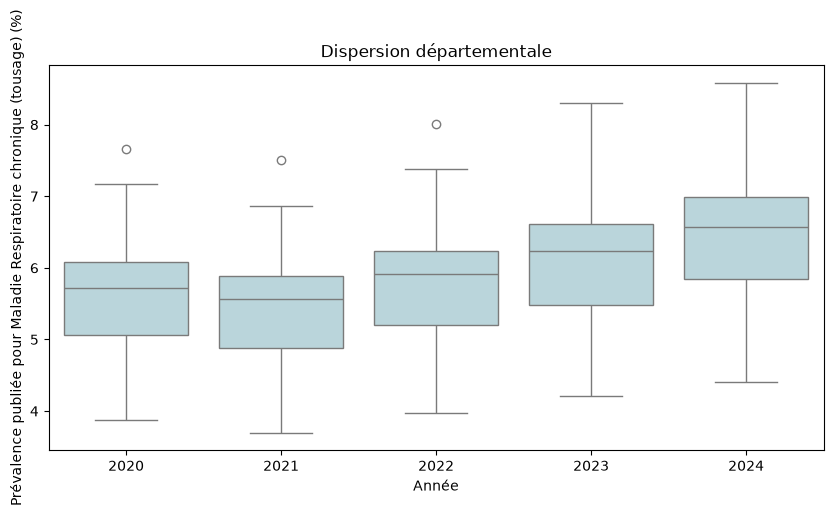

In [56]:
import seaborn as sns
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 5))

sns.boxplot(data=df_fusion, x='annee', y='prev_Maladie_Respi_Chronique_tsage_9', ax=ax, color="#b5d8e0")
ax.set_xlabel("Année"), 
ax.set_ylabel('Prévalence publiée pour Maladie Respiratoire chronique (tousage) (%)'), 
ax.set_title('Dispersion départementale')